<a href="https://colab.research.google.com/github/aashish7542/ai-learning/blob/main/phase-0-foundations/python/phase%200.3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is about Pandas and working with data, which will be cruical in making our final project of Phase 0.

In [5]:
import pandas as pd

df = pd.DataFrame({
    "size": [1000, 1500, 2000, 1800],
    "bedrooms": [2, 3, 4, None],
    "price": [200000, 280000, 350000, 310000]
})

red_line("Info")
df.info()
red_line("Head")
print(df.head)
red_line("shape")
print(df.shape)
red_line("describe")
df.describe()


   INFO

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   size      4 non-null      int64  
 1   bedrooms  3 non-null      float64
 2   price     4 non-null      int64  
dtypes: float64(1), int64(2)
memory usage: 228.0 bytes

   HEAD

<bound method NDFrame.head of    size  bedrooms   price
0  1000       2.0  200000
1  1500       3.0  280000
2  2000       4.0  350000
3  1800       NaN  310000>

   SHAPE

(4, 3)

   DESCRIBE



,size,bedrooms,price
count,4.000000,3.0,4.000000
mean,1575.000000,3.0,285000.000000
std,434.932945,1.0,63508.529611
min,1000.000000,2.0,200000.000000
25%,1375.000000,2.5,260000.000000
50%,1650.000000,3.0,295000.000000
75%,1850.000000,3.5,320000.000000
max,2000.000000,4.0,350000.000000


I have introduced a function below that will be used to separate the clusters of output, making it look better

In [3]:
def red_line(title=""):
    # Prints a thick red line with an optional title
    color_red = "\033[91m"
    color_reset = "\033[0m"
    line = "=" * 60
    if title:
        print(f"\n{color_red}{line}\n   {title.upper()}\n{line}{color_reset}\n")
    else:
        print(f"\n{color_red}{line}{color_reset}\n")

**Real world Datasets**
Now we are importing a datasets about exoplanets from a github repo: https://github.com/mwaskom/seaborn-data/blob/master/planets.csv

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/planets.csv"

df = pd.read_csv(url)

print(df.shape)
display(df.head())

print(df.isna().sum())

(1035, 6)


,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


method              0
number              0
orbital_period     43
mass              522
distance          227
year                0
dtype: int64


**Cleaning Data**
The cells below are about identifying unsual values and cleaning them, if necessary.

In [3]:
pd.crosstab(df["method"], df["mass"].isna())

mass,False,True
method,,
Astrometry,0,2
Eclipse Timing Variations,2,7
Imaging,0,38
Microlensing,0,23
Orbital Brightness Modulation,0,3
Pulsar Timing,0,5
Pulsation Timing Variations,0,1
Radial Velocity,510,43
Transit,1,396


In [6]:
clean = df.dropna(subset=["orbital_period", "distance"])

print(df.shape)
print(clean.shape)

(1035, 6)
(776, 6)


In [7]:
df.duplicated().sum()

np.int64(4)

In [17]:
df[df.duplicated(keep=False)]


,method,number,orbital_period,mass,distance,year
33,Imaging,1,NaN,NaN,NaN,2008
902,Microlensing,1,NaN,NaN,NaN,2008
903,Microlensing,1,NaN,NaN,NaN,2008
904,Microlensing,1,NaN,NaN,NaN,2009
923,Microlensing,1,NaN,NaN,NaN,2009
925,Microlensing,2,NaN,NaN,4080.0,2012
926,Microlensing,2,NaN,NaN,4080.0,2012
957,Imaging,1,NaN,NaN,NaN,2008


In [18]:
df[["orbital_period", "mass", "distance"]].describe()

,orbital_period,mass,distance
count,992.000000,513.000000,808.000000
mean,2002.917596,2.638161,264.069282
std,26014.728304,3.818617,733.116493
min,0.090706,0.003600,1.350000
25%,5.442540,0.229000,32.560000
50%,39.979500,1.260000,55.250000
75%,526.005000,3.040000,178.500000
max,730000.000000,25.000000,8500.000000


In [19]:
(df["orbital_period"] <= 0).sum()

np.int64(0)

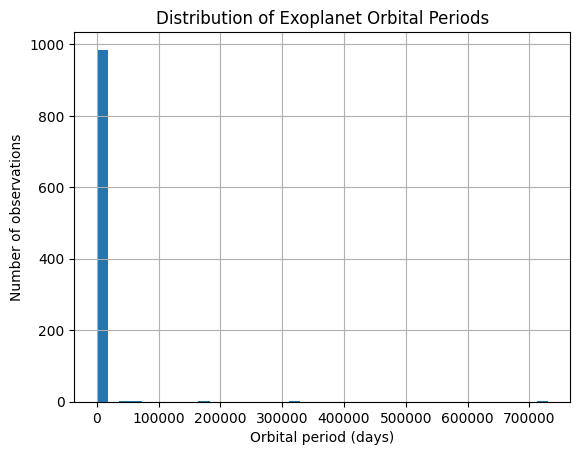

In [20]:
import matplotlib.pyplot as plt

df["orbital_period"].dropna().hist(bins=40)

plt.xlabel("Orbital period (days)")
plt.ylabel("Number of observations")
plt.title("Distribution of Exoplanet Orbital Periods")
plt.show()

**Since the histogram shows unusually large values in very small numbers, we will use a logathrimic function to analyse them.**

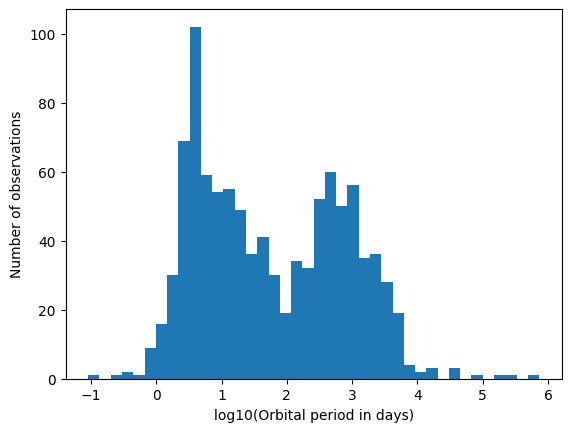

In [22]:
import numpy as np

periods = df["orbital_period"].dropna()

plt.hist(np.log10(periods), bins=40)
plt.xlabel("log10(Orbital period in days)")
plt.ylabel("Number of observations")
plt.show()

**Caught them**

The logarithmic distribution reveals that they all follow one single distributio, stg that histogram failed to show.

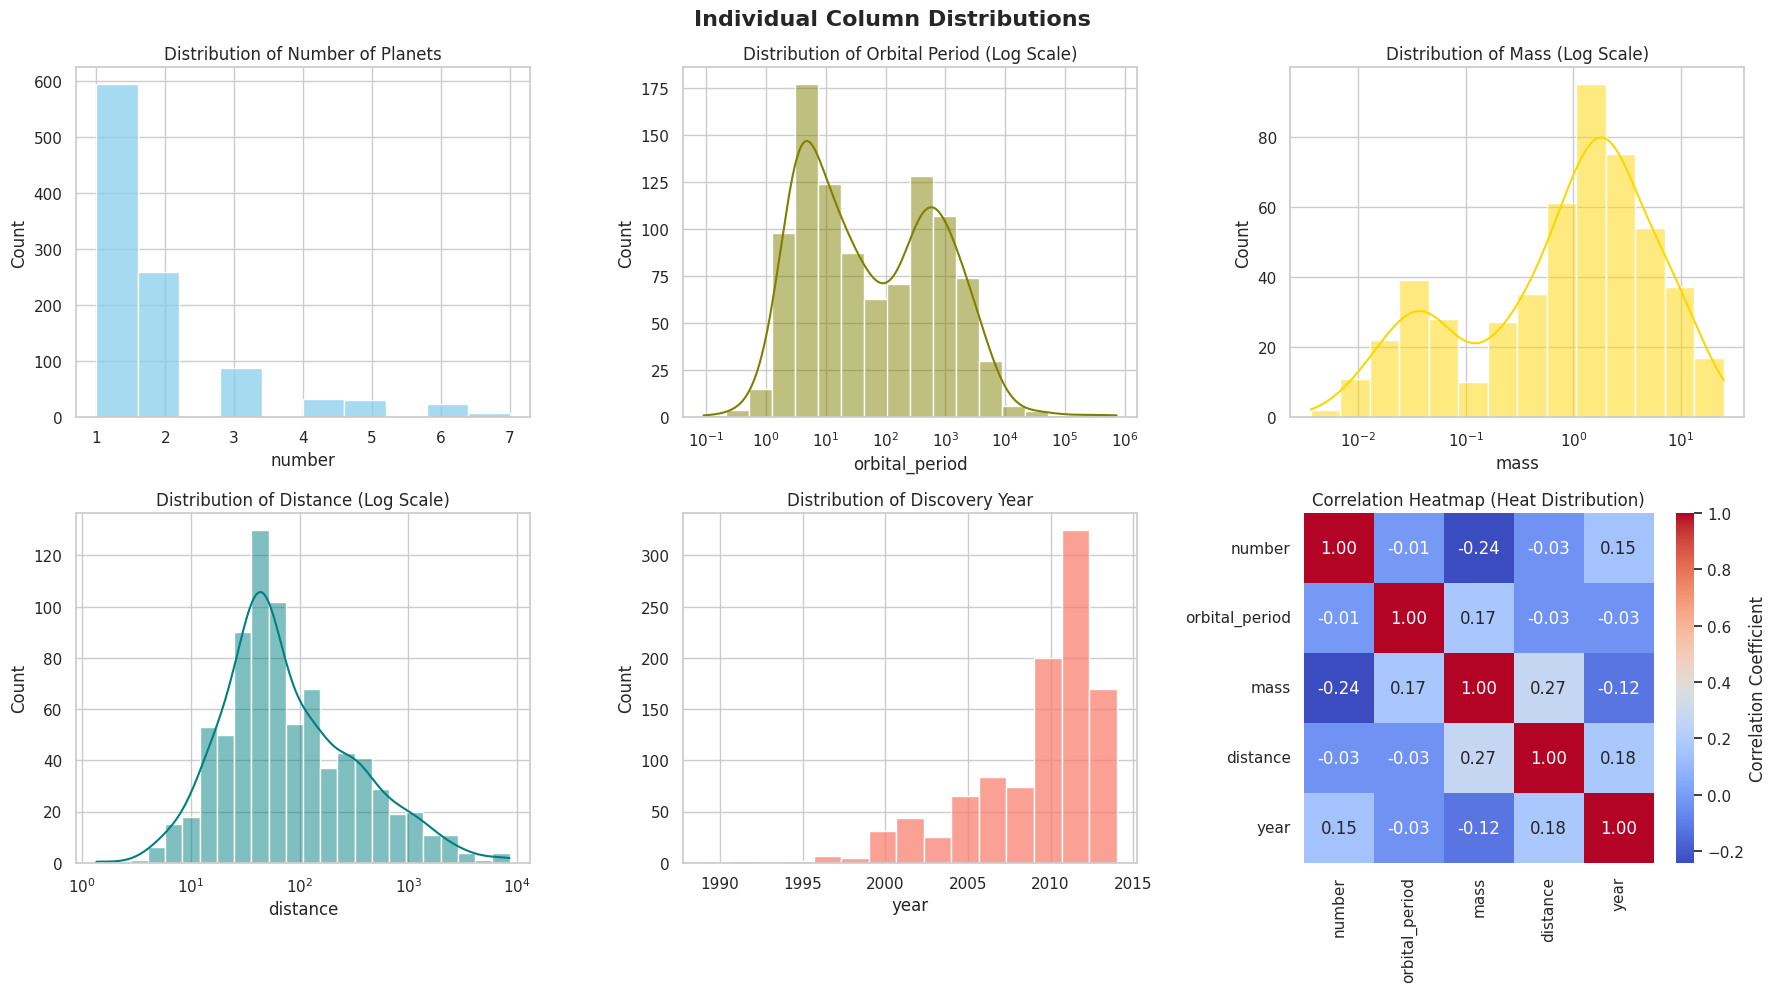

Generating Pairplot to show relationships between columns...


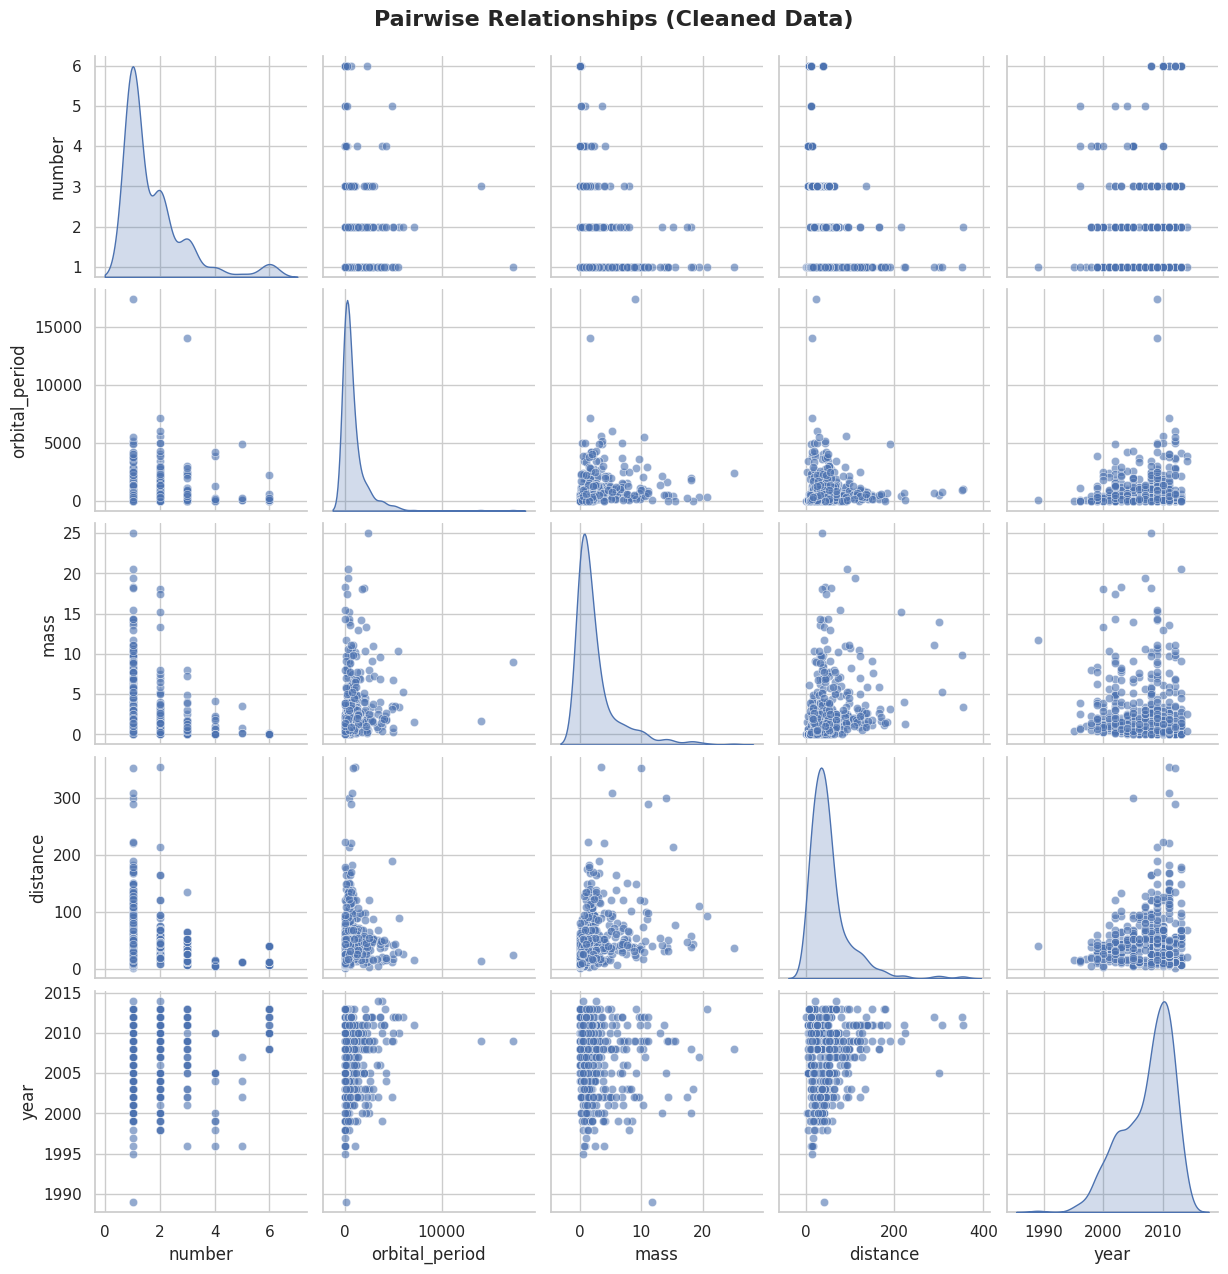

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set the style
sns.set_theme(style="whitegrid")

# 1. Select numeric columns for distribution and correlation
num_cols = ["number", "orbital_period", "mass", "distance", "year"]

# We'll use a log scale for skewed columns in the individual plots to make them readable
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Individual Column Distributions", fontsize=16, fontweight='bold')

# Plot Number
sns.histplot(df["number"], kde=False, ax=axes[0, 0], color="skyblue", bins=10)
axes[0, 0].set_title("Distribution of Number of Planets")

# Plot Orbital Period (Log Scale)
sns.histplot(df["orbital_period"].dropna(), kde=True, ax=axes[0, 1], color="olive", log_scale=True)
axes[0, 1].set_title("Distribution of Orbital Period (Log Scale)")

# Plot Mass (Log Scale)
sns.histplot(df["mass"].dropna(), kde=True, ax=axes[0, 2], color="gold", log_scale=True)
axes[0, 2].set_title("Distribution of Mass (Log Scale)")

# Plot Distance (Log Scale)
sns.histplot(df["distance"].dropna(), kde=True, ax=axes[1, 0], color="teal", log_scale=True)
axes[1, 0].set_title("Distribution of Distance (Log Scale)")

# Plot Year
sns.histplot(df["year"], kde=False, ax=axes[1, 1], color="salmon", bins=15)
axes[1, 1].set_title("Distribution of Discovery Year")

# 2. Heat distribution (Correlation Heatmap) in the last subplot
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True, ax=axes[1, 2], cbar_kws={'label': 'Correlation Coefficient'})
axes[1, 2].set_title("Correlation Heatmap (Heat Distribution)")

plt.tight_layout()
plt.show()

# 3. Distributions of their relations (Pairplot)
print("Generating Pairplot to show relationships between columns...")
# Use a subset of columns and drop NaNs for pairplot visualization
relation_plot = sns.pairplot(df[num_cols].dropna(), diag_kind="kde", plot_kws={'alpha': 0.6})
relation_plot.fig.suptitle("Pairwise Relationships (Cleaned Data)", y=1.02, fontsize=16, fontweight='bold')
plt.show()

In [25]:
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [24]:
df.groupby("method")["orbital_period"].median().sort_values()

,orbital_period
method,
Orbital Brightness Modulation,0.342887
Transit,5.714932
Transit Timing Variations,57.011000
Pulsar Timing,66.541900
Radial Velocity,360.200000
Astrometry,631.180000
Pulsation Timing Variations,1170.000000
Microlensing,3300.000000
Eclipse Timing Variations,4343.500000


Let's investigate whether heavier exoplanets tend to have longer orbital periods.

In [26]:
df[["mass", "orbital_period"]].corr()

,mass,orbital_period
mass,1.000000,0.173725
orbital_period,0.173725,1.000000


**Even though correlation is close to zero, it does necessarily mean that they have no relation. This correlation just checks for the linear relationship.**

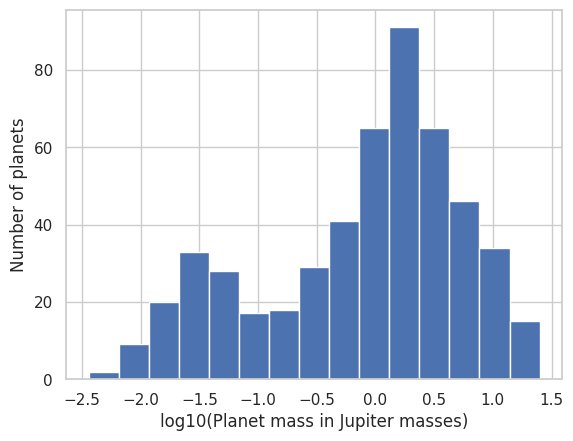

In [28]:
import matplotlib.pyplot as plt
import numpy as np

mass = df["mass"].dropna()

plt.hist(np.log10(mass), bins=15)
plt.xlabel("log10(Planet mass in Jupiter masses)")
plt.ylabel("Number of planets")
plt.show()

**Scatter Plot**

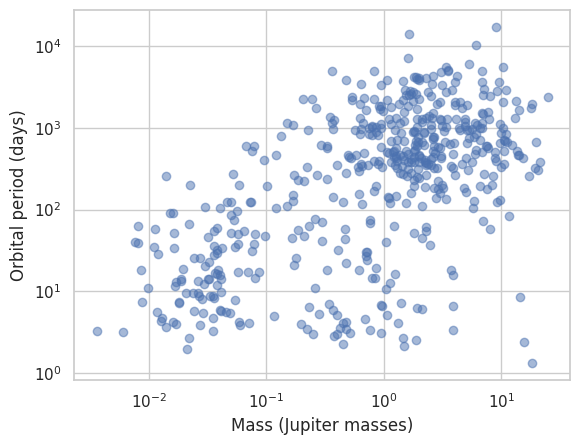

In [34]:
data = df[["mass", "orbital_period"]].dropna()

plt.scatter(data["mass"], data["orbital_period"], alpha=0.5)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Mass (Jupiter masses)")
plt.ylabel("Orbital period (days)")
plt.show()

**Perhaps we could add methods also in this**

In [35]:
import plotly.express as px

data = df.dropna(subset=["mass", "orbital_period"])

fig = px.scatter(
    data,
    x="mass",
    y="orbital_period",
    color="method",
    log_x=True,
    log_y=True,
    hover_data=["year", "distance"],
    opacity=0.6,
    title="Exoplanets by Discovery Method"
)

fig.show()

**Since Radial Velocity highly dominates this graph because of missing mass, we will plot using the Orbital Periods instead.**

Its a **BoxPlot** below, in logarithmic scale. If we do it in linear scale, things get messed up.

In [42]:
data = df[df["method"].isin(["Transit", "Radial Velocity"])]

fig = px.box(
    data,
    x="method",
    y="orbital_period",
    log_y=True,
    color="method",
    points="all",
    title="Orbital Period by Discovery Method"
)

fig.show()

**list out the number of data sets using each cateogry of methods**

In [37]:
method_counts = df["method"].value_counts()
display(method_counts)

,count
method,
Radial Velocity,553
Transit,397
Imaging,38
Microlensing,23
Eclipse Timing Variations,9
Pulsar Timing,5
Transit Timing Variations,4
Orbital Brightness Modulation,3
Astrometry,2


also include how many of them are missing

In [38]:
# Calculate total counts and missing counts for each column per discovery method
summary_df = df.groupby('method').agg(
    total_planets=('method', 'size'),
    missing_orbital_period=('orbital_period', lambda x: x.isna().sum()),
    missing_mass=('mass', lambda x: x.isna().sum()),
    missing_distance=('distance', lambda x: x.isna().sum())
).sort_values(by='total_planets', ascending=False)

display(summary_df)

,total_planets,missing_orbital_period,missing_mass,missing_distance
method,,,,
Radial Velocity,553,0,43,23
Transit,397,0,396,173
Imaging,38,26,38,6
Microlensing,23,16,23,13
Eclipse Timing Variations,9,0,7,5
Pulsar Timing,5,0,5,4
Transit Timing Variations,4,1,4,1
Orbital Brightness Modulation,3,0,3,1
Astrometry,2,0,2,0
